# Notebook 10: When Is Decay Markov?

**Goal:** Read Fermi's golden rule, the textbook route to exponential decay, as a statement about an indivisible
stochastic process, and find the Γ-only quantity that says when decay is Markov.

By the end of this notebook you will be able to:
- Show that survival in the textbook level-plus-band model has three regimes: a quadratic start whose rate is set by the
  agility ν of notebook 07, an exponential middle at the golden-rule rate κ, and a breakdown at the recurrence time
- Show that "a stochastic intermediate matrix exists" is too weak a test: the coarse "decayed or not" process passes it
  through both the quadratic start and the exponential middle
- Define the division-event defect, the change one division event would make, and split it into two pieces, one that shrinks
  with δ/κ and one that shrinks with κ/W: the golden rule's two textbook conditions, δ ≪ κ and κ ≪ W
- See that whether decay "is Markov" depends on what the observer tracks

In [1]:
import sys
import os
sys.path.insert(0, os.path.abspath('..'))

%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from isp.decay import DecayModel, coarse_gamma, negative_mass, division_defect

## 1. The Textbook Model

One level $b$ is coupled with strength $g$ to a band of $M$ levels $k_1,\dots,k_M$, equally spaced by $\delta$ and centred on $b$'s energy.
The band has width $W = M\delta$. The configurations are $b$ ("undecayed") and the band levels ("decayed into level $k$").
As in every notebook so far, the dynamics is $\Gamma(t\leftarrow 0) = |U(t)|^2$ with $U(t) = e^{-iHt}$.

Fermi's golden rule predicts exponential decay at the rate

$$\kappa = \frac{2\pi g^2}{\delta},$$

i.e. $2\pi$ × (coupling)² × (density of final states). Textbooks call this rate Γ; here Γ is reserved for transition matrices, so the rate is κ.
The derivation needs two conditions: the band must look continuous on the scale of the decay ($\delta \ll \kappa$), and wide compared with it ($\kappa \ll W$).

This section's model is deliberately small, so that its finite-size effects show up inside the plots of section 2.

In [2]:
m = DecayModel(M=250, delta=0.04, g=np.sqrt(0.1 * 0.04 / (2 * np.pi)))
kappa = m.rate

print(f"band: M = {m.M} levels, spacing δ = {m.delta}, bandwidth W = {m.bandwidth:.0f}")
print(f"golden-rule rate κ = 2πg²/δ = {kappa:.4f}   lifetime 1/κ = {1 / kappa:.0f}")
print(f"conditions: δ/κ = {m.delta / kappa:.2f}   κ/W = {kappa / m.bandwidth:.3f}")
print(f"agility of b (notebook 07): ν = {np.sqrt(m.nu2):.4f}")
print(f"recurrence time 2π/δ = {m.recurrence_time:.0f}")

G = m.gamma(5.0)
print(f"\nΓ(5 ← 0) is {G.shape[0]}×{G.shape[1]}; every column sums to 1: {np.allclose(G.sum(axis=0), 1)}")

band: M = 250 levels, spacing δ = 0.04, bandwidth W = 10
golden-rule rate κ = 2πg²/δ = 0.1000   lifetime 1/κ = 10
conditions: δ/κ = 0.40   κ/W = 0.010
agility of b (notebook 07): ν = 0.3989
recurrence time 2π/δ = 157

Γ(5 ← 0) is 251×251; every column sums to 1: True


## 2. Survival in Three Regimes

The survival probability is a single entry of Γ, $P(t) = \Gamma_{bb}(t\leftarrow 0)$, and its instantaneous decay rate is $r(t) = -\tfrac{d}{dt}\ln P(t)$.
The golden rule says $r = \kappa$. Notebook 07 says that at short times $P(t) \approx 1 - \nu^2 t^2$, so $r(t) \approx 2\nu^2 t$ starts at zero.

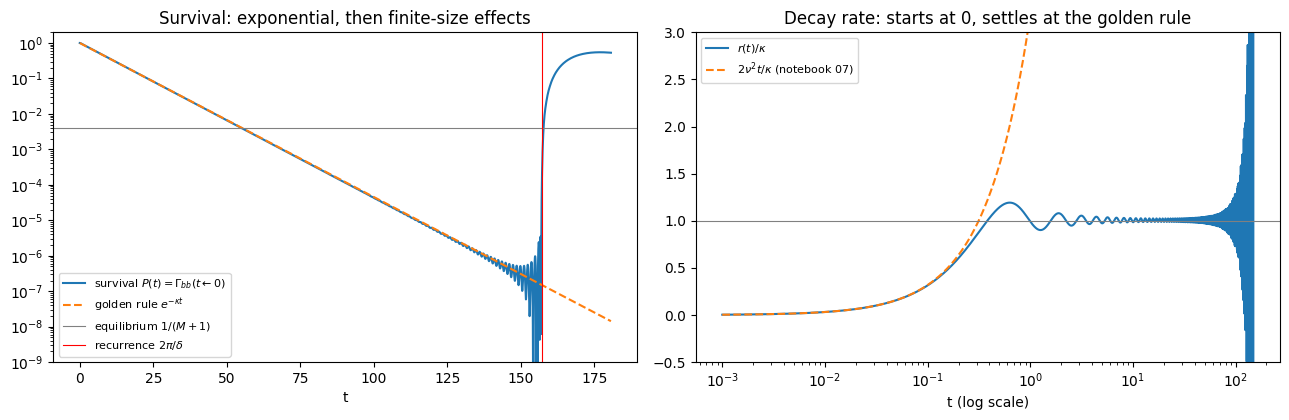

t =    0.01   r/κ = +0.032   2ν²t/κ =   0.032
t =    0.05   r/κ = +0.159   2ν²t/κ =   0.159
t =    0.20   r/κ = +0.604   2ν²t/κ =   0.638
t =    1.00   r/κ = +0.992   2ν²t/κ =   3.185
t =   10.01   r/κ = +0.985   2ν²t/κ =  31.859
t =   29.96   r/κ = +0.996   2ν²t/κ =  95.355
t =  100.11   r/κ = +1.156   2ν²t/κ = 318.659
t =  149.23   r/κ = +23.844   2ν²t/κ = 475.000

r/κ stays within 5% of 1 from t = 3.24 to t = 57.0


In [3]:
ts = np.linspace(0, 1.15 * m.recurrence_time, 6000)
P = m.survival(ts)
t_eq = np.log(m.M + 1) / kappa

tr = np.logspace(-3, np.log10(0.95 * m.recurrence_time), 4000)
r = -np.gradient(np.log(m.survival(tr)), tr)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
ax[0].semilogy(ts, P, label='survival $P(t)=\\Gamma_{bb}(t\\leftarrow 0)$')
ax[0].semilogy(ts, np.exp(-kappa * ts), '--', label='golden rule $e^{-\\kappa t}$')
ax[0].axhline(1 / (m.M + 1), color='gray', lw=0.8, label='equilibrium $1/(M+1)$')
ax[0].axvline(m.recurrence_time, color='red', lw=0.8, label='recurrence $2\\pi/\\delta$')
ax[0].set_ylim(1e-9, 2); ax[0].set_xlabel('t'); ax[0].legend(fontsize=8)
ax[0].set_title('Survival: exponential, then finite-size effects')

ax[1].semilogx(tr, r / kappa, label='$r(t)/\\kappa$')
ax[1].semilogx(tr, 2 * m.nu2 * tr / kappa, '--', label='$2\\nu^2 t/\\kappa$ (notebook 07)')
ax[1].axhline(1, color='gray', lw=0.8)
ax[1].set_ylim(-0.5, 3); ax[1].set_xlabel('t (log scale)'); ax[1].legend(fontsize=8)
ax[1].set_title('Decay rate: starts at 0, settles at the golden rule')
plt.tight_layout(); plt.show()

for t in [0.01, 0.05, 0.2, 1, 10, 30, 100, 150]:
    i = np.argmin(abs(tr - t))
    print(f"t = {tr[i]:7.2f}   r/κ = {r[i] / kappa:+.3f}   2ν²t/κ = {2 * m.nu2 * tr[i] / kappa:7.3f}")

ok = np.abs(r / kappa - 1) < 0.05
i10 = np.argmin(abs(tr - 10))
lo, hi = i10, i10
while lo > 0 and ok[lo - 1]: lo -= 1
while hi < len(tr) - 1 and ok[hi + 1]: hi += 1
print(f"\nr/κ stays within 5% of 1 from t = {tr[lo]:.2f} to t = {tr[hi]:.1f}")

## 3. Plain Divisibility Is Too Weak

Notebooks 02–05 asked whether $\Gamma(t\leftarrow 0) = D\,\Gamma(t'\leftarrow 0)$ for some **stochastic** $D$. The candidate is the derived intermediate
$D = \Gamma(t)\,\Gamma(t')^{-1}$; the process is divisible at $(t', t)$ when $D$ has no negative entries.

The golden rule is about "decayed or not", so first coarse-grain to two configurations, undecayed and decayed. The decayed column needs
a starting distribution over band levels; uniform is the natural choice. Then test every consecutive pair of times. Then run the same test
on the full process, with every band level as its own configuration.

In [4]:
grid = np.linspace(0, 1.15 * m.recurrence_time, 4001)
Pg = m.survival(grid)
neg = np.array([negative_mass(coarse_gamma(Pg[i + 1], m.M) @ np.linalg.inv(coarse_gamma(Pg[i], m.M)))
                for i in range(len(grid) - 1)])

first_bad = grid[1:][neg > 1e-12][0]
print("Coarse process {undecayed, decayed}:")
print(f"  first step with no stochastic intermediate: t ≈ {first_bad:.1f}")
print(f"  P(t) first drops below 1/(M+1):             t ≈ {grid[np.argmax(Pg < 1 / (m.M + 1))]:.1f}")
print(f"  ln(M+1)/κ:                                   t = {t_eq:.1f}")
print(f"  largest negative mass before that:           {neg[grid[1:] < first_bad - 1].max():.1e}")

print("\nFull process (all M+1 configurations), step of 2.5:")
for t1 in [0.5, 5, 20, 40]:
    D = m.gamma(t1 + 2.5) @ np.linalg.inv(m.gamma(t1))
    neg_cols = -np.clip(D, None, 0).sum(axis=0)
    print(f"  t' = {t1:5.1f}:  negative mass of D = {negative_mass(D):.1e}"
          f"   (b's own column: {neg_cols[0]:.1e}; worst band column: {neg_cols[1:].max():.1e};"
          f" all columns together: {neg_cols.sum():.1e})")

h = grid[1] - grid[0]
print(f"\nFull process, same step as the coarse test ({h:.3f}):")
for t1 in [0.05, 0.5, 1, 2, 5, 20, 50]:
    D = m.gamma(t1 + h) @ np.linalg.inv(m.gamma(t1))
    print(f"  t' = {t1:5.2f}:  negative mass of D = {negative_mass(D):.1e}")

Coarse process {undecayed, decayed}:
  first step with no stochastic intermediate: t ≈ 55.1
  P(t) first drops below 1/(M+1):             t ≈ 55.1
  ln(M+1)/κ:                                   t = 55.3
  largest negative mass before that:           0.0e+00

Full process (all M+1 configurations), step of 2.5:
  t' =   0.5:  negative mass of D = 8.6e-03   (b's own column: 8.6e-03; worst band column: 1.1e-04; all columns together: 1.6e-02)
  t' =   5.0:  negative mass of D = 1.0e-01   (b's own column: 1.0e-01; worst band column: 3.2e-03; all columns together: 2.0e-01)
  t' =  20.0:  negative mass of D = 8.2e-01   (b's own column: 8.2e-01; worst band column: 1.0e-01; all columns together: 1.8e+00)
  t' =  40.0:  negative mass of D = 2.7e-01   (b's own column: 2.7e-01; worst band column: 5.5e-02; all columns together: 5.9e-01)

Full process, same step as the coarse test (0.045):
  t' =  0.05:  negative mass of D = 0.0e+00
  t' =  0.50:  negative mass of D = 2.9e-07
  t' =  1.00:  negative 

## 4. The Division-Event Defect

A sharper question: **would a division event change anything?** If the environment records the configuration at time $t'$, the process
restarts from wherever the system is, and the statistics after a further time $s$ become $\Gamma(s)\,\Gamma(t')$ instead of $\Gamma(t'+s)$. The difference

$$\Delta(t', s) = \Gamma(t'+s) - \Gamma(s)\,\Gamma(t')$$

uses Γ alone. Δ = 0 means the event changes nothing, which is what "decay is Markov" means. For a system prepared undecayed, its survival
entry splits exactly into two pieces:

$$\Delta_{bb} = \underbrace{\big[P(t'+s) - P(t')\,P(s)\big]}_{\text{non-exponential survival}} \;-\; \underbrace{\textstyle\sum_k \Gamma_{bk}(s)\,\Gamma_{kb}(t')}_{\text{re-excitation}} .$$

The first piece is zero for all $t'$, $s$ exactly when $P$ is exponential. The second counts band levels, set loose by the event, that come back to $b$.
Both pieces are first measured in absolute terms; the last block of the next cell compares the whole change with survival itself.

Short times: a division event raises survival by 2ν²t's
  t' = s = 0.01:  Δ_bb = -3.181e-05   −2ν²t's = -3.183e-05
  t' = s = 0.02:  Δ_bb = -1.271e-04   −2ν²t's = -1.273e-04
  t' = s = 0.05:  Δ_bb = -7.856e-04   −2ν²t's = -7.958e-04

Vary the spacing δ at fixed width W = 10 (one event at t' = 2/κ, then s = 1/κ):
  δ/κ = 0.400:  re-excitation = 2.779e-02   non-exponential (relative) = -1.284e-02
  δ/κ = 0.200:  re-excitation = 1.390e-02   non-exponential (relative) = -1.283e-02
  δ/κ = 0.100:  re-excitation = 6.948e-03   non-exponential (relative) = -1.283e-02


  δ/κ = 0.050:  re-excitation = 3.474e-03   non-exponential (relative) = -1.283e-02

Vary the width W at fixed δ = κ/10 (survival only):
  κ/W = 0.0400:  non-exponential (relative) = -5.194e-02   −(4/π)κ/W = -5.093e-02
  κ/W = 0.0200:  non-exponential (relative) = -2.584e-02   −(4/π)κ/W = -2.546e-02
  κ/W = 0.0100:  non-exponential (relative) = -1.283e-02   −(4/π)κ/W = -1.273e-02


  κ/W = 0.0050:  non-exponential (relative) = -6.361e-03   −(4/π)κ/W = -6.366e-03


  κ/W = 0.0025:  non-exponential (relative) = -3.148e-03   −(4/π)κ/W = -3.183e-03

Relative to survival (W = 10, s = 1/κ): survival with one event at t' ÷ survival without it


  δ/κ = 0.05, ln(κ/δ) = 3.0:  κt'=1: 1.03   κt'=2: 1.08   κt'=3: 1.23   κt'=4: 1.64   κt'=8: 37.26
  δ/κ = 0.40, ln(κ/δ) = 0.9:  κt'=1: 1.14   κt'=2: 1.57   κt'=3: 2.77   κt'=4: 6.06   κt'=8: 291.42


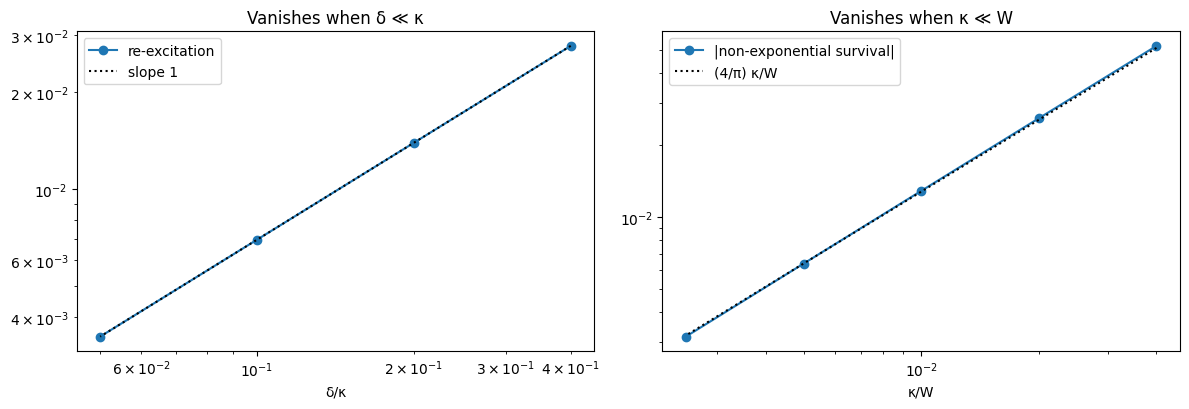

In [5]:
print("Short times: a division event raises survival by 2ν²t's")
for t1 in [0.01, 0.02, 0.05]:
    d = division_defect(m, t1, t1)
    print(f"  t' = s = {t1}:  Δ_bb = {d['survival']:+.3e}   −2ν²t's = {-2 * m.nu2 * t1 * t1:+.3e}")

kappa0 = 0.1
def band_model(M, W):
    delta = W / M
    return DecayModel(M=M, delta=delta, g=np.sqrt(kappa0 * delta / (2 * np.pi)))

t1, s = 2 / kappa0, 1 / kappa0

print("\nVary the spacing δ at fixed width W = 10 (one event at t' = 2/κ, then s = 1/κ):")
rows_d = []
for M in [250, 500, 1000, 2000]:
    mm = band_model(M, 10.0)
    d = division_defect(mm, t1, s)
    f_rel = d['factorization'] / mm.survival([t1 + s])[0]
    rows_d.append((mm.delta / kappa0, d['reexcitation']))
    print(f"  δ/κ = {mm.delta / kappa0:.3f}:  re-excitation = {d['reexcitation']:.3e}   non-exponential (relative) = {f_rel:+.3e}")

print("\nVary the width W at fixed δ = κ/10 (survival only):")
rows_W = []
for W in [2.5, 5, 10, 20, 40]:
    mm = band_model(int(round(10 * W / kappa0)), W)
    Pa, Pb, Pc = mm.survival([s, t1, t1 + s])
    f_rel = (Pc - Pb * Pa) / Pc
    rows_W.append((kappa0 / W, f_rel))
    print(f"  κ/W = {kappa0 / W:.4f}:  non-exponential (relative) = {f_rel:+.3e}   −(4/π)κ/W = {-4 / np.pi * kappa0 / W:+.3e}")

print("\nRelative to survival (W = 10, s = 1/κ): survival with one event at t' ÷ survival without it")
for M in [2000, 250]:
    mm = band_model(M, 10.0)
    ratios = []
    for k_t1 in [1, 2, 3, 4, 8]:
        P_without = mm.survival([k_t1 / kappa0 + s])[0]
        P_with = P_without - division_defect(mm, k_t1 / kappa0, s)['survival']
        ratios.append(f"κt'={k_t1}: {P_with / P_without:.2f}")
    print(f"  δ/κ = {mm.delta / kappa0:.2f}, ln(κ/δ) = {np.log(kappa0 / mm.delta):.1f}:  " + "   ".join(ratios))

rows_d, rows_W = np.array(rows_d), np.array(rows_W)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].loglog(rows_d[:, 0], rows_d[:, 1], 'o-', label='re-excitation')
ax[0].loglog(rows_d[:, 0], rows_d[0, 1] * rows_d[:, 0] / rows_d[0, 0], 'k:', label='slope 1')
ax[0].set_xlabel('δ/κ'); ax[0].set_title('Vanishes when δ ≪ κ'); ax[0].legend()
ax[1].loglog(rows_W[:, 0], -rows_W[:, 1], 'o-', label='|non-exponential survival|')
ax[1].loglog(rows_W[:, 0], 4 / np.pi * rows_W[:, 0], 'k:', label='(4/π) κ/W')
ax[1].set_xlabel('κ/W'); ax[1].set_title('Vanishes when κ ≪ W'); ax[1].legend()
plt.tight_layout(); plt.show()

## 5. It Depends on What the Observer Tracks

Section 4 looked at one entry, "still undecayed?". The same division event also changes **which** band level the system is found in.

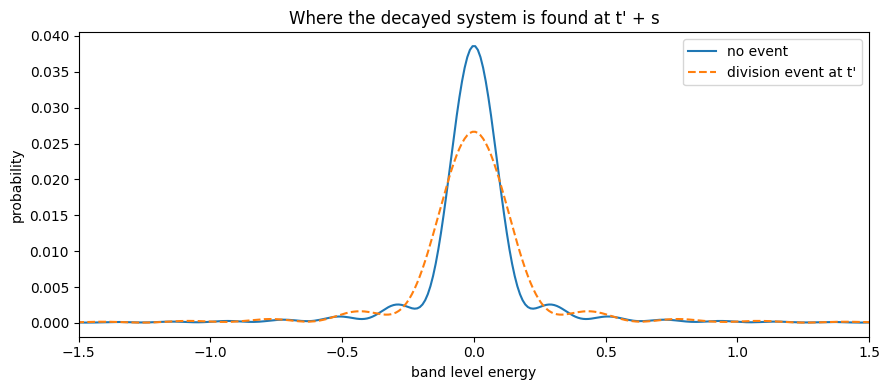

One event at t', observed at t' + s = t' + 1/κ (L1 distances, each between 0 and 2):


  κt' = 1, M =  250:  'decayed or not' 2|Δ_bb| = 3.7e-02   band populations = 0.4941   ÷ e^(-κt'/2) = 0.81
  κt' = 1, M = 2000:  'decayed or not' 2|Δ_bb| = 7.6e-03   band populations = 0.4856   ÷ e^(-κt'/2) = 0.80


  κt' = 1, M = 4000:  'decayed or not' 2|Δ_bb| = 5.6e-03   band populations = 0.4852   ÷ e^(-κt'/2) = 0.80
  κt' = 2, M =  250:  'decayed or not' 2|Δ_bb| = 5.7e-02   band populations = 0.3263   ÷ e^(-κt'/2) = 0.89
  κt' = 2, M = 2000:  'decayed or not' 2|Δ_bb| = 8.2e-03   band populations = 0.3237   ÷ e^(-κt'/2) = 0.88


  κt' = 2, M = 4000:  'decayed or not' 2|Δ_bb| = 4.7e-03   band populations = 0.3230   ÷ e^(-κt'/2) = 0.88
  κt' = 4, M =  250:  'decayed or not' 2|Δ_bb| = 6.7e-02   band populations = 0.1257   ÷ e^(-κt'/2) = 0.93
  κt' = 4, M = 2000:  'decayed or not' 2|Δ_bb| = 8.5e-03   band populations = 0.1212   ÷ e^(-κt'/2) = 0.90


  κt' = 4, M = 4000:  'decayed or not' 2|Δ_bb| = 4.3e-03   band populations = 0.1206   ÷ e^(-κt'/2) = 0.89
  κt' = 6, M =  250:  'decayed or not' 2|Δ_bb| = 6.8e-02   band populations = 0.0606   ÷ e^(-κt'/2) = 1.22


  κt' = 6, M = 2000:  'decayed or not' 2|Δ_bb| = 8.5e-03   band populations = 0.0447   ÷ e^(-κt'/2) = 0.90


  κt' = 6, M = 4000:  'decayed or not' 2|Δ_bb| = 4.3e-03   band populations = 0.0442   ÷ e^(-κt'/2) = 0.89
  κt' = 8, M =  250:  'decayed or not' 2|Δ_bb| = 6.8e-02   band populations = 0.0436   ÷ e^(-κt'/2) = 2.38


  κt' = 8, M = 2000:  'decayed or not' 2|Δ_bb| = 8.5e-03   band populations = 0.0168   ÷ e^(-κt'/2) = 0.92


  κt' = 8, M = 4000:  'decayed or not' 2|Δ_bb| = 4.3e-03   band populations = 0.0163   ÷ e^(-κt'/2) = 0.89


In [6]:
mm = band_model(1000, 10.0)
eps = (np.arange(mm.M) - (mm.M - 1) / 2) * mm.delta
without = mm.column(t1 + s)[1:]
with_event = (mm.gamma(s) @ mm.column(t1))[1:]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(eps, without, label='no event')
ax.plot(eps, with_event, '--', label="division event at t'")
ax.set_xlim(-1.5, 1.5); ax.set_xlabel('band level energy'); ax.set_ylabel('probability')
ax.set_title("Where the decayed system is found at t' + s"); ax.legend()
plt.tight_layout(); plt.show()

print("One event at t', observed at t' + s = t' + 1/κ (L1 distances, each between 0 and 2):")
models = {M: band_model(M, 10.0) for M in [250, 2000, 4000]}
for k_t1 in [1, 2, 4, 6, 8]:
    for M, mod in models.items():
        d = division_defect(mod, k_t1 / kappa0, s)
        print(f"  κt' = {k_t1}, M = {M:4d}:  'decayed or not' 2|Δ_bb| = {2 * abs(d['survival']):.1e}"
              f"   band populations = {d['band_l1']:.4f}   ÷ e^(-κt'/2) = {d['band_l1'] / np.exp(-k_t1 / 2):.2f}")

## Summary

- **Three regimes.** Survival starts as $1 - \nu^2 t^2$ (rate $2\nu^2 t$, from the agility of notebook 07). Its rate reaches the golden-rule κ at times
  of order $1/W$ and, after some ringing, stays within 5% of it (here from $t \approx 3$ to $t \approx 57$). Finite-size effects then take over, ending in a revival that
  begins at the recurrence time $2\pi/\delta$.
- **Plain divisibility cannot find the window.** The coarse "decayed or not" process is divisible from $t'$ to $t$ exactly when
  $-1/M \le (P(t) - p_{\rm eq})/(P(t') - p_{\rm eq}) \le 1$, with $p_{\rm eq} = 1/(M+1)$. It passes through the quadratic start and the
  exponential middle, and first fails when $P$ falls below the equilibrium $1/(M+1)$, at $t \approx \ln(M+1)/\kappa$: a finite-size effect, not the golden rule.
  As $M \to \infty$ the condition becomes "survival never increases", the amplitude-damping criterion of Breuer–Laine–Piilo (2009).
  The full process fails it at every sampled time from $t' \approx 1$ on (same step), including inside the exponential window. One test is too lenient, the other too strict.
- **The division-event defect** $\Delta = \Gamma(t'+s) - \Gamma(s)\Gamma(t')$ is the right quantity. For "decayed or not" it splits into two pieces:
  - re-excitation, proportional to $\delta/\kappa$ in absolute terms: small when $\delta \ll \kappa$;
  - non-exponential survival, $\approx -(4/\pi)\,\kappa/W$ relative: small when $\kappa \ll W$.

  In this model each of the golden rule's two textbook conditions controls one piece. But relative to the surviving population, re-excitation
  grows roughly as $e^{\kappa t'}$: with $\delta/\kappa = 0.05$ and $s = 1/\kappa$, one event raises survival by 3%, 8%, 23% and 64% at $\kappa t' = 1, 2, 3, 4$.
  So under both conditions a division event barely changes survival only while $e^{-\kappa t'} \gg \delta/\kappa$, i.e. for $t' \lesssim \ln(\kappa/\delta)/\kappa$.
  Like the coarse test's $\ln(M+1)/\kappa$, this is a finite-size limit.
- **Short times.** A division event raises survival by $2\nu^2 t' s$: the seed of the Zeno effect (notebook 11).
- **It depends on the observer.** The same event changes the band populations by an amount that fades as $e^{-\kappa t'/2}$, the rate of $\sqrt{P(t')}$,
  approaching $\approx 0.89\,e^{-\kappa t'/2}$ for $s = 1/\kappa$ once the band is dense ($M = 2000$ and $4000$ agree within 5% for $\kappa t' \le 8$;
  $M = 250$ shows a finite-size floor from $\kappa t' \approx 6$). For $t' \lesssim \ln(\kappa/\delta)/\kappa$, decay is close to Markov for "decayed or not" well before it is for "which level".

Caveats: one flat band, centred on $b$; the decayed column of the coarse process assumes a uniform start; the $(4/\pi)$ coefficient is a
first-order result; the "barely changes survival" window and the $0.89$ coefficient are measured numerically for $s = 1/\kappa$ only.

Prior work: the three regimes are reviewed by Facchi and Pascazio (2001); the defect Δ is the Kolmogorov-consistency test of Milz et al. (2020);
the $-(4/\pi)\kappa/W$ piece is $1 - Z$, the wave-function renormalization of Facchi, Nakazato and Pascazio (2001); the $-2\nu^2t's$ short-time
term is the standard seed of the Zeno effect; the coarse test's large-$M$ limit is Breuer–Laine–Piilo (2009); and that a coarse observer sees
Markov decay into a wide, dense band is the textbook Weisskopf–Wigner (Born–Markov) argument, restated here in Γ. The observer-relative
piece of section 5 is the interference term between the undecayed and decayed amplitudes. That measurement reshapes the decay-product spectrum is known in kind; this exact Γ statement was not found in our searches, and its coefficient settles only once $\kappa t' \gtrsim 3$ (at $\kappa t' = 1$ the change is 0.49, i.e. $0.80\,e^{-1/2}$).